# Где интернет-магазин теряет покупателей
Воронка, когорты, Чёрная пятница и дизайн A/B-теста на данных магазина косметики (REES46, октябрь-ноябрь 2019).

**Как запускать:** меню *Kernel → Restart & Run All* (или по одной ячейке, Shift+Enter).
Тяжёлые вычисления делает PostgreSQL, в Python приходят только итоговые таблицы.

## 0. Настройки и подключение к базе

In [3]:
import os
import math
from getpass import getpass

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from scipy.stats import chi2_contingency
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from statsmodels.stats.proportion import (
    proportions_ztest, confint_proportions_2indep, proportion_effectsize)
from statsmodels.stats.power import NormalIndPower

DATA_DIR = "../data"      # где лежат 2019-Oct.csv и 2019-Nov.csv
SQL_DIR = "../sql"
IMG_DIR = "../images"
LOAD_DATA = True          # после первой успешной загрузки поставь False, чтобы не грузить заново

# Пароль спрашивается при запуске и не сохраняется в блокноте, поэтому его безопасно выкладывать на GitHub
password = os.environ.get("PGPASSWORD") or getpass("Пароль пользователя postgres: ")

url = URL.create("postgresql+psycopg2", username="postgres", password=password,
                 host="localhost", port=5432, database="cosmetics")
engine = create_engine(url, connect_args={"client_encoding": "utf8"})

def read_sql_file(name):
    with open(os.path.join(SQL_DIR, name), encoding="utf-8") as f:
        return f.read()

def run_query(name):
    """Выполняет файл с ОДНИМ запросом SELECT и возвращает таблицу pandas."""
    return pd.read_sql(text(read_sql_file(name)), engine)

def run_script(name):
    """Выполняет файл с несколькими командами (CREATE, DROP, INDEX) без результата."""
    with engine.begin() as conn:
        conn.exec_driver_sql(read_sql_file(name))

def fmt_p(p):
    """p-value для отчёта: очень маленькие значения пишем как p < 0,001, а не 0."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

sns.set_theme(style="whitegrid")
GREEN, ACCENT = "#4A6741", "#C8754A"

with engine.connect() as conn:
    print(conn.exec_driver_sql("SELECT version()").scalar())

Пароль пользователя postgres:  ········


PostgreSQL 17.6 on x86_64-windows, compiled by msvc-19.44.35213, 64-bit


## 1. Загрузка CSV в таблицу `events_raw`
Самый быстрый способ загрузить большой CSV в PostgreSQL: `COPY ... FROM STDIN`. Файл передаётся потоком, без построчных INSERT.
На 9 млн строк уходит несколько минут.

In [5]:
if LOAD_DATA:
    run_script("01_create_tables.sql")
    raw = engine.raw_connection()
    try:
        cur = raw.cursor()
        for fname in ["2019-Oct.csv", "2019-Nov.csv"]:
            with open(os.path.join(DATA_DIR, fname), encoding="utf-8") as f:
                cur.copy_expert("COPY events_raw FROM STDIN WITH (FORMAT csv, HEADER true)", f)
            print(f"{fname}: загружено {cur.rowcount:,} строк")
        raw.commit()
    finally:
        raw.close()
else:
    print("Загрузка пропущена (LOAD_DATA = False)")

2019-Oct.csv: загружено 4,102,283 строк
2019-Nov.csv: загружено 4,635,837 строк


## 2. Проверка качества данных
Четыре проверки из `02_checks.sql`: объём и период, типы событий, полные дубли, пропуски и неверные цены.

In [7]:
checks = [q.strip() for q in read_sql_file("02_checks.sql").split(";") if "SELECT" in q]
overview, event_types, dups, gaps = [pd.read_sql(text(q), engine) for q in checks]
display(overview, event_types, dups, gaps)

,rows_total,users,first_event,last_event
0,8738120,713100,2019-10-01 00:00:00 UTC,2019-11-30 23:59:58 UTC


,event_type,events
0,view,3938296
1,cart,2544192
2,remove_from_cart,1687591
3,purchase,568041


,duplicate_rows
0,459848


,no_brand,no_session,bad_price
0,3645290,1450,17728


## 3. Чистая таблица `events`
Убираем полные дубли (`DISTINCT`), строки с ценой ≤ 0, превращаем дату из текста в `timestamp`, пустой бренд заменяем на `NULL`.

In [9]:
run_script("03_clean_table.sql")
rows_raw = int(overview.loc[0, "rows_total"])
rows_clean = pd.read_sql(text("SELECT count(*) AS n FROM events"), engine).loc[0, "n"]
print(f"Было {rows_raw:,} строк, осталось {rows_clean:,}, удалено {rows_raw - rows_clean:,} "
      f"({(rows_raw - rows_clean) / rows_raw:.2%})")

Было 8,738,120 строк, осталось 8,260,755, удалено 477,365 (5.46%)


## 4. Воронка: просмотр → корзина → покупка
Считается **по пользователям** (а не по событиям) и **строго**: на шаг попадает только тот, кто прошёл предыдущие.

,step,users,conv_from_prev,conv_from_start
0,Просмотр,"692,550",nan%,100.0%
1,Корзина,"191,487",27.6%,27.6%
2,Покупка,"49,468",25.8%,7.1%


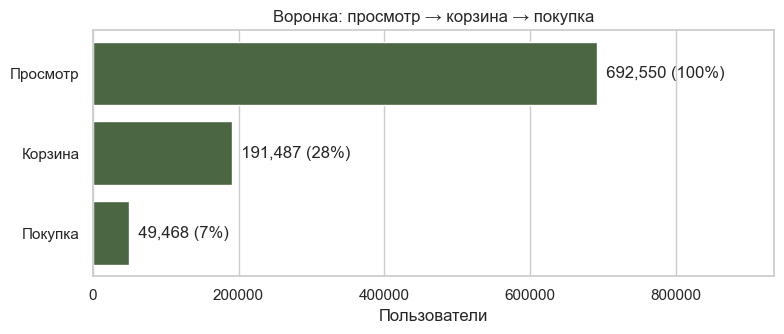

In [11]:
funnel = run_query("04_funnel.sql").T.reset_index()
funnel.columns = ["step", "users"]
funnel["step"] = ["Просмотр", "Корзина", "Покупка"]
funnel["conv_from_prev"] = funnel["users"] / funnel["users"].shift(1)    # из предыдущего шага
funnel["conv_from_start"] = funnel["users"] / funnel["users"].iloc[0]    # от начала воронки
display(funnel.style.format({"users": "{:,.0f}", "conv_from_prev": "{:.1%}", "conv_from_start": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(funnel["step"], funnel["users"], color=GREEN)
ax.invert_yaxis()
ax.set_xlim(0, funnel["users"].max() * 1.35)
for i, row in funnel.iterrows():
    ax.text(row["users"], i, f"  {row['users']:,.0f} ({row['conv_from_start']:.0%})", va="center")
ax.set_title("Воронка: просмотр → корзина → покупка")
ax.set_xlabel("Пользователи")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/funnel.png", dpi=150)
plt.show()

## 5. Недельные когорты и удержание
Когорта: пользователи, впервые пришедшие в одну неделю. В ячейке указана доля когорты, активная через N недель.

Ограничения: данные начинаются 1 октября, поэтому «первый визит» в октябре не всегда означает нового клиента (левое цензурирование); у поздних когорт короткий хвост наблюдения.

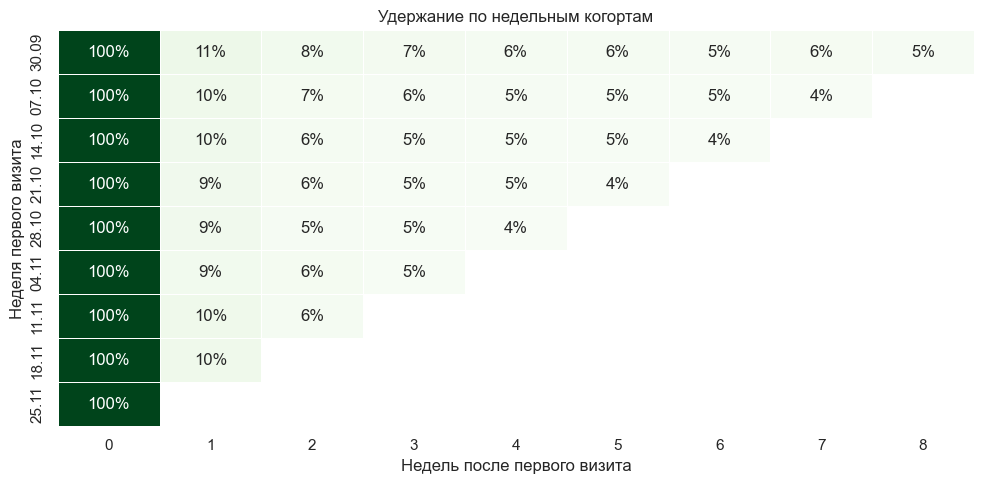

Удержание на неделе 1: медиана по когортам 9.8% (от 8.6% до 11.2%)


In [13]:
cohorts = run_query("05_cohorts.sql")
pivot = cohorts.pivot(index="cohort_week", columns="week_number", values="users")
retention = pivot.div(pivot[0], axis=0)
retention.index = pd.to_datetime(retention.index).strftime("%d.%m")

plt.figure(figsize=(10, 5))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Greens", cbar=False, linewidths=0.5)
plt.title("Удержание по недельным когортам")
plt.xlabel("Недель после первого визита")
plt.ylabel("Неделя первого визита")
plt.grid(False)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/cohorts.png", dpi=150)
plt.show()

week1 = retention[1].dropna()
print(f"Удержание на неделе 1: медиана по когортам {week1.median():.1%} (от {week1.min():.1%} до {week1.max():.1%})")

## 6. Метрики по дням
Активные пользователи, выручка и доля покупателей по дням. Серым выделена неделя Чёрной пятницы (25-30 ноября).

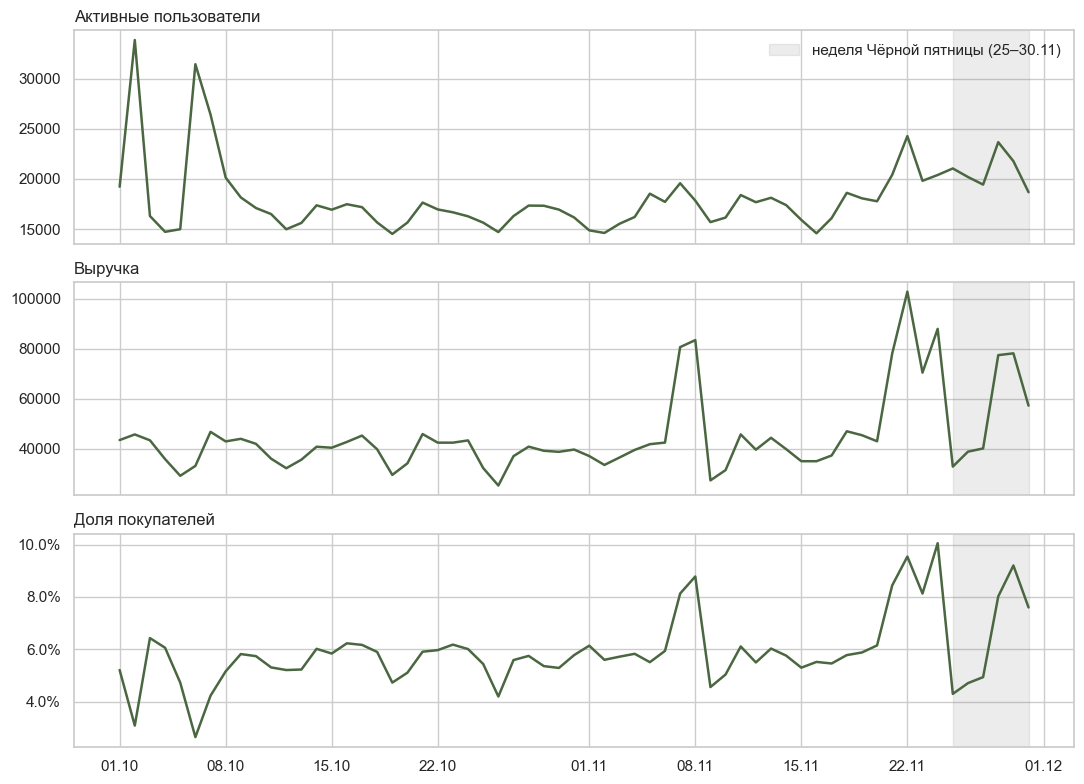

,day,dau,revenue,buyer_share,avg_order_value
52,2019-11-22,24267,102854.32,0.0954,43.73
54,2019-11-24,20388,87953.90,0.1005,42.22
38,2019-11-08,17835,83474.63,0.0878,52.57
37,2019-11-07,19566,80664.26,0.0813,49.58
59,2019-11-29,21765,78179.16,0.0920,38.40


Средняя выручка в день: обычные дни ноября 50,252, неделя Чёрной пятницы 54,132
Средний чек: обычные дни 41.79, Чёрная пятница 39.09


In [15]:
daily = run_query("07_daily_metrics.sql")
daily["day"] = pd.to_datetime(daily["day"])

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
panels = [("dau", "Активные пользователи", "{:,.0f}"),
          ("revenue", "Выручка", "{:,.0f}"),
          ("buyer_share", "Доля покупателей", "{:.1%}")]
for ax, (col, title, _) in zip(axes, panels):
    ax.plot(daily["day"], daily[col].astype(float), color=GREEN, linewidth=1.8)
    ax.axvspan(pd.Timestamp("2019-11-25"), pd.Timestamp("2019-11-30"), color="grey", alpha=0.15,
               label="неделя Чёрной пятницы (25–30.11)")
    ax.set_title(title, loc="left")
axes[0].legend(loc="upper right", frameon=False)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/daily_metrics.png", dpi=150)
plt.show()

# Дни с самой высокой выручкой: совпадают ли они с неделей Чёрной пятницы?
top_days = daily.nlargest(5, "revenue")[["day", "dau", "revenue", "buyer_share", "avg_order_value"]]
display(top_days)

bf_mask = daily["day"].between("2019-11-25", "2019-11-30")
nov_mask = daily["day"].between("2019-11-01", "2019-11-24")
print(f"Средняя выручка в день: обычные дни ноября {daily.loc[nov_mask, 'revenue'].mean():,.0f}, "
      f"неделя Чёрной пятницы {daily.loc[bf_mask, 'revenue'].mean():,.0f}")
print(f"Средний чек: обычные дни {daily.loc[nov_mask, 'avg_order_value'].astype(float).mean():.2f}, "
      f"Чёрная пятница {daily.loc[bf_mask, 'avg_order_value'].astype(float).mean():.2f}")

## 7. Чёрная пятница: z-тест для двух долей
Метрика: доля сессий с корзиной, закончившихся покупкой.
H0: конверсия в неделю Чёрной пятницы и в обычные дни ноября одинаковая. H1: отличается.

Важно: это **наблюдательные данные, а не эксперимент**. В распродажу приходит другая аудитория, поэтому разница показывает связь, но не доказывает, что её вызвали скидки.

In [17]:
bf = run_query("06_black_friday.sql").set_index("period")
x = [bf.loc["black_friday_week", "sessions_with_purchase"], bf.loc["regular", "sessions_with_purchase"]]
n = [bf.loc["black_friday_week", "sessions_with_cart"], bf.loc["regular", "sessions_with_cart"]]
p_bf, p_reg = x[0] / n[0], x[1] / n[1]

z, p_value = proportions_ztest(count=x, nobs=n)
ci_low, ci_high = confint_proportions_2indep(x[0], n[0], x[1], n[1], compare="diff")

display(bf)
print(f"Конверсия «корзина → покупка»: Чёрная пятница {p_bf:.1%}, обычные дни {p_reg:.1%}")
print(f"Разница {100 * (p_bf - p_reg):+.1f} п.п., 95% ДИ [{100 * ci_low:+.1f}; {100 * ci_high:+.1f}] п.п., "
      f"z = {z:.2f}, {fmt_p(p_value)}")

,days,sessions_with_cart,sessions_with_purchase
period,,,
black_friday_week,6,46495,6552
regular,24,166207,22949


Конверсия «корзина → покупка»: Чёрная пятница 14.1%, обычные дни 13.8%
Разница +0.3 п.п., 95% ДИ [-0.1; +0.6] п.п., z = 1.57, p = 0.117


## 8. Ценовые сегменты: где корзину бросают чаще
Товары в корзине делятся на 4 равные группы по цене (квартили, оконная функция `ntile`). Для каждой группы считаем долю товаров, купленных в той же сессии.
Хи-квадрат проверяет, отличается ли конверсия между сегментами в целом.

,segment,carted_items,bought_items,cart_to_purchase
0,Q1: 0.05–1.73,524737,77817,0.1483
1,Q2: 1.73–3.22,524737,66647,0.1270
2,Q3: 3.22–5.54,524737,63314,0.1207
3,Q4: 5.54–327.78,524737,69059,0.1316


Хи-квадрат = 1921.3, df = 3, p < 0.001, V Крамера = 0.030


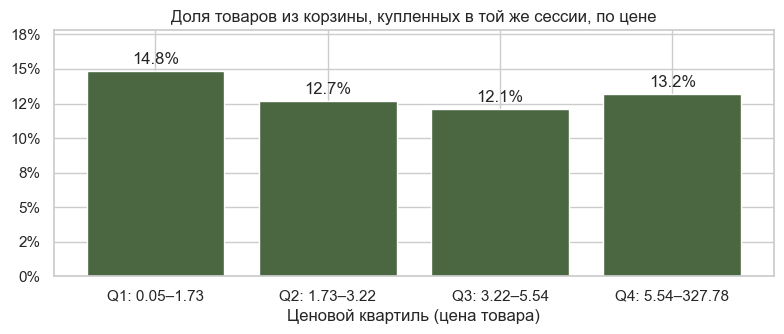

In [19]:
seg = run_query("08_price_segments.sql")
seg["segment"] = seg.apply(lambda r: f"Q{int(r.price_quartile)}: {r.min_price:.2f}–{r.max_price:.2f}", axis=1)
display(seg[["segment", "carted_items", "bought_items", "cart_to_purchase"]])

table = [seg["bought_items"], seg["carted_items"] - seg["bought_items"]]
chi2, p_chi, dof, _ = chi2_contingency(table)
# V Крамера показывает размер эффекта: при 2 млн наблюдений значимой будет почти любая разница,
# поэтому важно не только p, но и то, насколько разница велика (0.1 слабая, 0.3 средняя)
n_total = seg["carted_items"].sum()          # всего товаров в корзинах
k = min(2, len(seg))                          # таблица 2 x 4 -> меньшая сторона = 2
cramers_v = math.sqrt(chi2 / (n_total * (k - 1)))
print(f"Хи-квадрат = {chi2:.1f}, df = {dof}, {fmt_p(p_chi)}, V Крамера = {cramers_v:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(seg["segment"], seg["cart_to_purchase"].astype(float), color=GREEN)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in seg["cart_to_purchase"].astype(float)], padding=3)
ax.set_ylim(0, seg["cart_to_purchase"].astype(float).max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("Доля товаров из корзины, купленных в той же сессии, по цене")
ax.set_xlabel("Ценовой квартиль (цена товара)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/price_segments.png", dpi=150)
plt.show()

## 9. Дизайн A/B-теста
Гипотеза (пример): *если показывать в корзине, сколько осталось до бесплатной доставки, конверсия «корзина → покупка» вырастет.*

Сколько сессий нужно в каждой группе, чтобы заметить рост на MDE (5 / 10 / 15% от текущего уровня) при α = 0,05 и мощности 0,8, и сколько это дней при текущем трафике. Длительность округляется вверх до целых недель.

In [21]:
p0 = p_reg
daily_carts = bf.loc["regular", "sessions_with_cart"] / bf.loc["regular", "days"]

rows = []
for mde in [0.05, 0.10, 0.15]:
    p1 = p0 * (1 + mde)
    effect = proportion_effectsize(p1, p0)
    n_group = math.ceil(NormalIndPower().solve_power(
        effect_size=effect, alpha=0.05, power=0.8, ratio=1, alternative="two-sided"))
    days = math.ceil(2 * n_group / daily_carts)
    rows.append({"MDE": f"{mde:.0%}", "было": f"{p0:.1%}", "цель": f"{p1:.1%}",
                 "сессий в группе": n_group, "дней": days, "недель (округл.)": math.ceil(days / 7)})
ab_plan = pd.DataFrame(rows)
print(f"Сессий с корзиной в обычный день: {daily_carts:,.0f}")
display(ab_plan)

Сессий с корзиной в обычный день: 6,925


,MDE,было,цель,сессий в группе,дней,недель (округл.)
0,5%,13.8%,14.5%,40011,12,2
1,10%,13.8%,15.2%,10202,3,1
2,15%,13.8%,15.9%,4621,2,1


## 10. Сводка для README

In [23]:
print("=== ДАННЫЕ ===")
print(f"Строк исходно: {rows_raw:,}; после очистки: {rows_clean:,}; пользователей: {int(overview.loc[0, 'users']):,}")
print(f"Дубли: {int(dups.iloc[0, 0]):,}; цена <= 0: {int(gaps.loc[0, 'bad_price']):,}; без бренда: {int(gaps.loc[0, 'no_brand']):,} "
      f"({gaps.loc[0, 'no_brand'] / rows_raw:.1%}); без сессии: {int(gaps.loc[0, 'no_session']):,}")
print("\n=== ВОРОНКА ===")
for _, r in funnel.iterrows():
    prev = "" if pd.isna(r["conv_from_prev"]) else f", из предыдущего шага {r['conv_from_prev']:.1%}"
    print(f"{r['step']}: {r['users']:,.0f}{prev}")
print("\n=== КОГОРТЫ ===")
print(f"Удержание на неделе 1: медиана {week1.median():.1%}")
print("\n=== ЧЁРНАЯ ПЯТНИЦА ===")
print(f"{p_bf:.1%} против {p_reg:.1%}, разница {100 * (p_bf - p_reg):+.1f} п.п. "
      f"[{100 * ci_low:+.1f}; {100 * ci_high:+.1f}], {fmt_p(p_value)}")
print("Топ-5 дней по выручке:")
for _, r in top_days.iterrows():
    print(f"  {r['day']:%d.%m}: выручка {float(r['revenue']):,.0f}, доля покупателей {float(r['buyer_share']):.1%}")
print("\n=== ЦЕНОВЫЕ СЕГМЕНТЫ ===")
for _, r in seg.iterrows():
    print(f"{r['segment']}: {float(r['cart_to_purchase']):.1%}")
print(f"Хи-квадрат: {fmt_p(p_chi)}, V Крамера = {cramers_v:.3f}")
print("\n=== A/B-ТЕСТ ===")
print(ab_plan.to_string(index=False))

=== ДАННЫЕ ===
Строк исходно: 8,738,120; после очистки: 8,260,755; пользователей: 713,100
Дубли: 459,848; цена <= 0: 17,728; без бренда: 3,645,290 (41.7%); без сессии: 1,450

=== ВОРОНКА ===
Просмотр: 692,550
Корзина: 191,487, из предыдущего шага 27.6%
Покупка: 49,468, из предыдущего шага 25.8%

=== КОГОРТЫ ===
Удержание на неделе 1: медиана 9.8%

=== ЧЁРНАЯ ПЯТНИЦА ===
14.1% против 13.8%, разница +0.3 п.п. [-0.1; +0.6], p = 0.117
Топ-5 дней по выручке:
  22.11: выручка 102,854, доля покупателей 9.5%
  24.11: выручка 87,954, доля покупателей 10.1%
  08.11: выручка 83,475, доля покупателей 8.8%
  07.11: выручка 80,664, доля покупателей 8.1%
  29.11: выручка 78,179, доля покупателей 9.2%

=== ЦЕНОВЫЕ СЕГМЕНТЫ ===
Q1: 0.05–1.73: 14.8%
Q2: 1.73–3.22: 12.7%
Q3: 3.22–5.54: 12.1%
Q4: 5.54–327.78: 13.2%
Хи-квадрат: p < 0.001, V Крамера = 0.030

=== A/B-ТЕСТ ===
MDE  было  цель  сессий в группе  дней  недель (округл.)
 5% 13.8% 14.5%            40011    12                 2
10% 13.8% 15.2%     